# Student Exam Performance Predictor
MAAI-7102 — Assignment 1

A reproducible proof of concept for the Academic Support Office, using only the 13 observations supplied in the assignment. Scores are expressed in exam-score points. The analysis connects problem definition, exploration, model training, evaluation, and recommendation.

## Stage 1 — Project definition and SDLC plan
### Project requirements
The Academic Support Office needs a prototype that explores whether study hours are associated with exam performance. Its input is the supplied study-hour and exam-score observations, with StudyHours serving as the model’s only predictor. Its outputs include descriptive statistics, a structured data table, labeled plots, test predictions, and Mean Absolute Error (MAE). The trained model must estimate the score for 7.5 study hours and explain why a prediction at 100 hours should not be trusted.

### SDLC plan
- **Requirements:** Use the exact supplied data, examine its relationship, predict exam scores, and explain reliability and limitations.
- **Design:** Store numerical arrays, construct and inspect a table, visualize the relationship, split observations, fit on training data, evaluate on held-out data, and interpret results.
- **Implementation:** Use NumPy for statistics, Pandas for inspection and filtering, Matplotlib for plots, and scikit-learn for splitting, Linear Regression, predictions, and MAE.
- **Testing:** Check data integrity and input shapes, ensure training and test rows are disjoint, compare statistics across libraries, verify prediction counts, and independently check MAE.
- **Improvement:** Collect a larger representative sample and consider prior grades, attendance, sleep, and course difficulty in a future version.

**Workflow:** Supplied data → NumPy profile → Pandas inspection → scatter plot → train/test split → Linear Regression → predictions and MAE → recommendation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 11})

Matplotlib is building the font cache; this may take a moment.


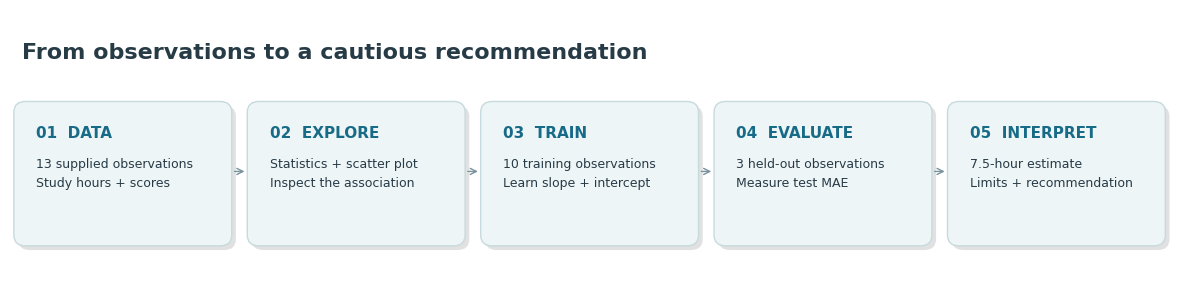

In [2]:
from matplotlib.patches import FancyBboxPatch
from matplotlib import patheffects

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.set(xlim=(0, 12), ylim=(0, 3.2))
ax.axis("off")
workflow_steps = [
    ("01  DATA", "13 supplied observations\nStudy hours + scores"),
    ("02  EXPLORE", "Statistics + scatter plot\nInspect the association"),
    ("03  TRAIN", "10 training observations\nLearn slope + intercept"),
    ("04  EVALUATE", "3 held-out observations\nMeasure test MAE"),
    ("05  INTERPRET", "7.5-hour estimate\nLimits + recommendation"),
]
for index, (title, description) in enumerate(workflow_steps):
    x = 0.12 + index * 2.4
    card = FancyBboxPatch((x, 0.65), 2.08, 1.45,
                         boxstyle="round,pad=0.08,rounding_size=0.12",
                         facecolor="#eef5f6", edgecolor="#c7dadd", linewidth=1)
    card.set_path_effects([patheffects.SimplePatchShadow(offset=(3, -3), alpha=0.16),
                          patheffects.Normal()])
    ax.add_patch(card)
    ax.text(x + 0.15, 1.77, title, color="#176b87", weight="bold", fontsize=11)
    ax.text(x + 0.15, 1.23, description, color="#273b47", fontsize=9, linespacing=1.6)
    if index < 4:
        ax.annotate("", xy=(x + 2.32, 1.4), xytext=(x + 2.16, 1.4),
                    arrowprops={"arrowstyle": "->", "color": "#7a929d"})
ax.text(0.12, 2.65, "From observations to a cautious recommendation", fontsize=16,
        weight="bold", color="#273b47")
fig.tight_layout()
fig.savefig(output_dir / "project_workflow.png", dpi=160)
plt.show()

## Stage 2 — Numerical data setup and basic statistics
The two arrays preserve the supplied observation order. Statistics and the above-average count are calculated from the arrays.

In [3]:
study_hours = np.array([1.0, 2.0, 2.5, 3.0, 4.0, 4.5, 5.0, 6.0, 6.5, 7.0, 8.0, 9.0, 10.0])
exam_scores = np.array([42, 48, 51, 55, 62, 65, 69, 75, 78, 82, 87, 91, 95])
assert study_hours.shape == exam_scores.shape == (13,)
assert np.isfinite(study_hours).all() and np.isfinite(exam_scores).all()
print(f"StudyHours observations: {study_hours.size}")
print(f"ExamScore observations: {exam_scores.size}")
mean_exam_score = np.mean(exam_scores)
numerical_profile = pd.Series({
    "Number of observations": exam_scores.size,
    "Average study hours": np.mean(study_hours),
    "Average exam score": mean_exam_score,
    "Minimum exam score": np.min(exam_scores),
    "Maximum exam score": np.max(exam_scores),
    "Exam-score standard deviation (population, ddof=0)": np.std(exam_scores),
})
display(numerical_profile.to_frame("Value"))
above_average_mask = exam_scores > np.mean(exam_scores)
print("Above-average Boolean comparison:", above_average_mask)
print("Students above the mean exam score:", np.count_nonzero(above_average_mask))

StudyHours observations: 13
ExamScore observations: 13


,Value
Number of observations,13.000000
Average study hours,5.269231
Average exam score,69.230769
Minimum exam score,42.000000
Maximum exam score,95.000000
"Exam-score standard deviation (population, ddof=0)",16.465133


Above-average Boolean comparison: [False False False False False False False  True  True  True  True  True
  True]
Students above the mean exam score: 6


The expression `exam_scores > np.mean(exam_scores)` returns a Boolean array with one entry per observation: True means that score exceeds the dataset mean. Counting True entries gives the number of above-average performers without manually inspecting rows.

In [4]:
display(Markdown(f"The {exam_scores.size} observations average **{np.mean(study_hours):.2f} study hours** and **{mean_exam_score:.2f} score points**. Scores span **{np.min(exam_scores)}–{np.max(exam_scores)}**, with a population standard deviation of **{np.std(exam_scores):.2f} points**, indicating meaningful variation in performance."))

The 13 observations average **5.27 study hours** and **69.23 score points**. Scores span **42–95**, with a population standard deviation of **16.47 points**, indicating meaningful variation in performance.

## Stage 3 — Structured dataset and data inspection
`df.head()` previews the first five observations and their column labels. `df.shape` reports the number of rows and columns before adding the derived feature. `df.describe()` summarizes count, mean, sample standard deviation, minimum, quartiles, and maximum for each numerical column.

In [5]:
df = pd.DataFrame({"StudyHours": study_hours, "ExamScore": exam_scores})
print("First five observations:")
display(df.head())
print("Initial DataFrame shape (rows, columns):", df.shape)
print("Numerical summary:")
display(df.describe())
assert not df.isna().any().any()
assert np.isclose(df["ExamScore"].mean(), mean_exam_score)
assert np.isclose(df["StudyHours"].mean(), np.mean(study_hours))
assert np.isclose(df["ExamScore"].std(), np.std(exam_scores, ddof=1))
df["AboveAverage"] = df["ExamScore"] > df["ExamScore"].mean()
print("Dataset with calculated AboveAverage feature:")
display(df)
stakeholder_rows = df[(df["StudyHours"] >= 6) & (df["ExamScore"] >= 75)]
print("Students studying at least 6 hours and scoring at least 75:")
display(stakeholder_rows)

First five observations:


,StudyHours,ExamScore
0,1.0,42
1,2.0,48
2,2.5,51
3,3.0,55
4,4.0,62


Initial DataFrame shape (rows, columns): (13, 2)
Numerical summary:


,StudyHours,ExamScore
count,13.000000,13.000000
mean,5.269231,69.230769
std,2.781002,17.137453
min,1.000000,42.000000
25%,3.000000,55.000000
50%,5.000000,69.000000
75%,7.000000,82.000000
max,10.000000,95.000000


Dataset with calculated AboveAverage feature:


,StudyHours,ExamScore,AboveAverage
0,1.0,42,False
1,2.0,48,False
2,2.5,51,False
3,3.0,55,False
4,4.0,62,False
5,4.5,65,False
6,5.0,69,False
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True


Students studying at least 6 hours and scoring at least 75:


,StudyHours,ExamScore,AboveAverage
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True
10,8.0,87,True
11,9.0,91,True
12,10.0,95,True


The query returns six observations, from 6 to 10 study hours and scores from 75 to 95. AboveAverage is a descriptive column only; it is derived from the target and must not be used as a model input.

The means, counts, and extrema agree with the NumPy profile. Pandas defaults to sample standard deviation (`ddof=1`), while NumPy defaults to population standard deviation (`ddof=0`); comparing the same convention resolves the apparent difference.

A NumPy array is useful for compact numerical operations on values of one type. A Pandas DataFrame adds labeled columns and row alignment, making inspection, calculated columns, and combined stakeholder filters easier to express and interpret.

## Stage 4 — Exploratory visualization
The raw scatter plot is inspected before fitting the model.

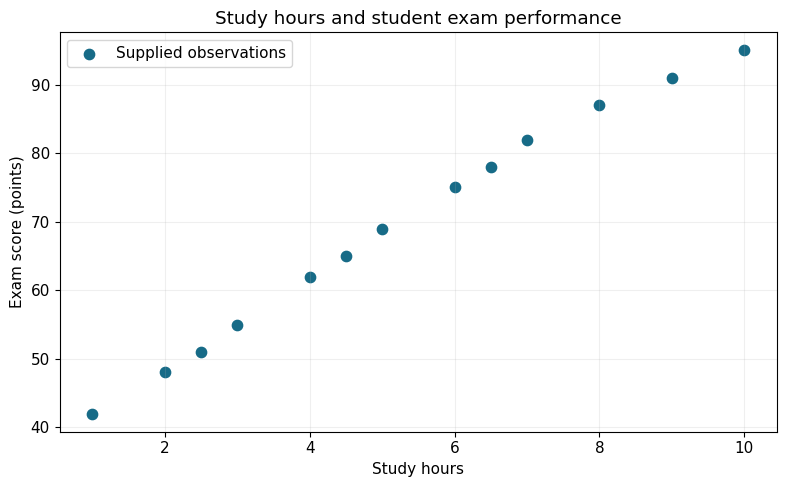

In [6]:
def plot_relationship():
    fig, ax = plt.subplots()
    ax.scatter(study_hours, exam_scores, color="#176b87", s=55, label="Supplied observations")
    ax.set(title="Study hours and student exam performance", xlabel="Study hours", ylabel="Exam score (points)")
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()
    return fig

scatter_figure = plot_relationship()
scatter_figure.savefig(output_dir / "study_hours_scatter.png", dpi=160)
plt.show()

The scatter plot shows a strong positive association: higher study hours accompany higher exam scores. The observations follow a roughly linear pattern, with some flattening at the highest hours. There are no obvious isolated unusual points; this association alone does not establish causation.

The fitted line will be added after training in Stage 5. It summarizes the model’s estimated score across the observed hours, allowing comparison between individual observations and the model’s trend.

## Stage 5 — Linear Regression model
X contains only StudyHours in two-dimensional form; y contains the corresponding ExamScore values. A fixed random split reserves 20% of observations for testing.

In [7]:
X = df[["StudyHours"]].to_numpy()
y = df["ExamScore"].to_numpy()
print("X shape:", X.shape)
print("y shape:", y.shape)
X_train, X_test, y_train, y_test, train_indices, test_indices = train_test_split(
    X, y, np.arange(len(df)), test_size=0.2, random_state=42
)
assert X.shape == (13, 1) and y.shape == (13,)
assert set(train_indices).isdisjoint(test_indices)
assert len(train_indices) + len(test_indices) == len(df)
print("Training observations:", len(y_train))
print("Test observations:", len(y_test))
model = LinearRegression()
model.fit(X_train, y_train)
print(f"Learned coefficient: {model.coef_[0]:.6f} points per study hour")
print(f"Learned intercept: {model.intercept_:.6f} points")
predictions = model.predict(X_test)
assert predictions.shape == y_test.shape
comparison = pd.DataFrame({"Observation index": test_indices, "StudyHours": X_test[:, 0],
                           "Actual ExamScore": y_test, "Predicted ExamScore": predictions})
display(comparison)
comparison.to_csv(output_dir / "test_predictions.csv", index=False)

X shape: (13, 1)
y shape: (13,)
Training observations: 10
Test observations: 3
Learned coefficient: 6.071273 points per study hour
Learned intercept: 37.232942 points


,Observation index,StudyHours,Actual ExamScore,Predicted ExamScore
0,11,9.0,91,91.874402
1,9,7.0,82,79.731856
2,0,1.0,42,43.304216


The training set has ten observations and the test set has three. Holding observations out checks predictions on data not used to estimate the parameters, although three examples provide very limited evaluation evidence.

`model.fit(X_train, y_train)` learns a slope and intercept that minimize squared training errors. `model.predict(X_test)` applies those learned parameters to each test input and returns predicted score values. The coefficient is the fitted change in predicted exam-score points associated with one additional study hour. The intercept is the model’s value at zero hours, outside the observed range, and should not automatically be interpreted as a realistic student outcome.

In [8]:
# Calculate the practical prediction separately so both the plot and evaluation use it.
prediction_7_5 = model.predict(np.array([[7.5]]))[0]

The fitted equation is **predicted score = 37.2329 + 6.0713 × study hours**. One additional study hour is associated with approximately **6.07 additional predicted score points** in this fitted model.

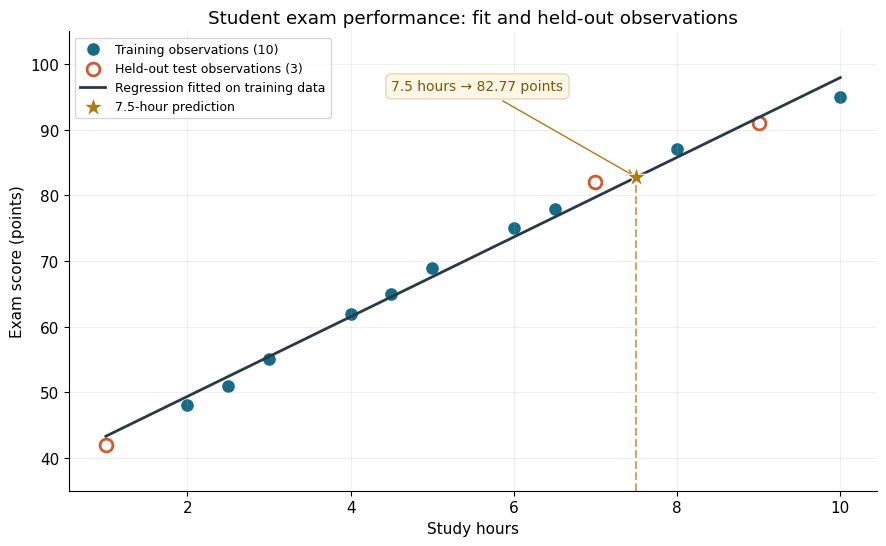

In [9]:
display(Markdown(f"The fitted equation is **predicted score = {model.intercept_:.4f} + {model.coef_[0]:.4f} × study hours**. One additional study hour is associated with approximately **{model.coef_[0]:.2f} additional predicted score points** in this fitted model."))
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.scatter(X_train[:, 0], y_train, s=65, color="#176b87", label="Training observations (10)")
ax.scatter(X_test[:, 0], y_test, s=85, facecolors="white", edgecolors="#d05a32",
           linewidths=2, label="Held-out test observations (3)")
line_hours = np.linspace(study_hours.min(), study_hours.max(), 200).reshape(-1, 1)
ax.plot(line_hours[:, 0], model.predict(line_hours), color="#273b47", linewidth=2,
        label="Regression fitted on training data")
ax.scatter([7.5], [prediction_7_5], marker="*", s=230, color="#b17a14",
           edgecolor="white", linewidth=0.8, zorder=5, label="7.5-hour prediction")
ax.plot([7.5, 7.5], [35, prediction_7_5], linestyle="--", color="#b17a14", alpha=0.65)
ax.annotate(f"7.5 hours → {prediction_7_5:.2f} points", xy=(7.5, prediction_7_5),
            xytext=(4.5, 96), fontsize=10, color="#80570c",
            arrowprops={"arrowstyle": "->", "color": "#b17a14"},
            bbox={"boxstyle": "round,pad=0.4", "fc": "#fff7e5", "ec": "#e7d8b2"})
ax.set(title="Student exam performance: fit and held-out observations",
       xlabel="Study hours", ylabel="Exam score (points)", ylim=(35, 105))
ax.grid(alpha=0.18)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(output_dir / "study_hours_regression.png", dpi=160)
plt.show()

The regression line closely follows the overall upward pattern, while individual points do not lie exactly on it. It provides an explicit prediction rule that the scatter alone does not provide; it is generated from the model fitted only on training observations. The filled teal points identify training observations, while the orange outlined points identify held-out observations. The star shows the model’s 7.5-hour estimate; its dashed guide connects the input to the fitted line. These visual cues do not change the split or the fitted model.

## Stage 6 — Model evaluation and practical prediction
MAE is computed on the held-out test scores. Predictions are left as the model produces them so that the boundary example exposes the extrapolation problem.

In [10]:
mae = mean_absolute_error(y_test, predictions)
prediction_100 = model.predict(np.array([[100.0]]))[0]
print(f"Test Mean Absolute Error (MAE): {mae:.4f} exam-score points")
print(f"Predicted score at 7.5 study hours: {prediction_7_5:.4f} points")
print(f"Boundary demonstration at 100 study hours: {prediction_100:.4f} points")
print(f"Observed study-hour range: {study_hours.min():.1f}–{study_hours.max():.1f} hours")
assert np.isclose(mae, np.mean(np.abs(y_test - predictions)))
assert np.isfinite(predictions).all()

Test Mean Absolute Error (MAE): 1.4823 exam-score points
Predicted score at 7.5 study hours: 82.7675 points
Boundary demonstration at 100 study hours: 644.3603 points
Observed study-hour range: 1.0–10.0 hours


In [11]:
display(Markdown(f"On these three test observations, predictions differ from actual scores by **{mae:.2f} points on average in absolute terms**. This is an observed average error, not a guaranteed bound for any future student. The **{prediction_7_5:.2f}-point** estimate for 7.5 hours is an interpolation-style use within the observed 1–10-hour range."))

On these three test observations, predictions differ from actual scores by **1.48 points on average in absolute terms**. This is an observed average error, not a guaranteed bound for any future student. The **82.77-point** estimate for 7.5 hours is an interpolation-style use within the observed 1–10-hour range.

### Reading the test errors visually
Each horizontal segment links an actual score to its prediction for one held-out observation. Longer segments indicate larger absolute errors; MAE averages the three segment lengths in score points.

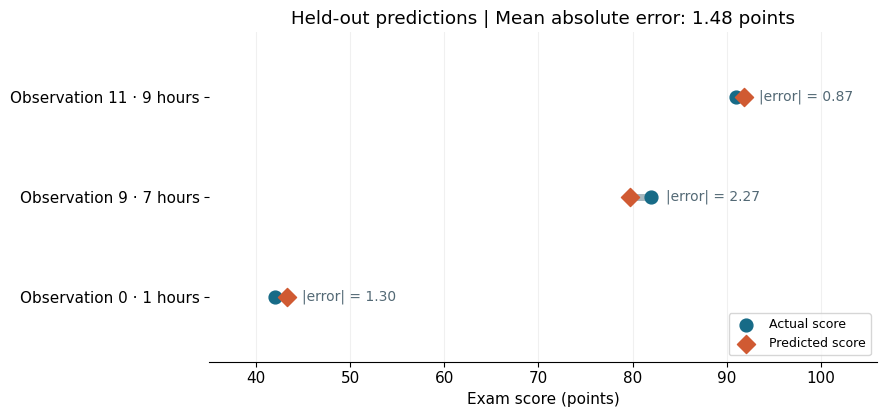

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.3))
positions = np.arange(len(y_test))
for row, actual, predicted in zip(positions, y_test, predictions):
    ax.plot([actual, predicted], [row, row], color="#a7b8bf", linewidth=5, zorder=1)
    ax.annotate(f"|error| = {abs(actual - predicted):.2f}",
                xy=(max(actual, predicted) + 1.6, row), va="center", fontsize=10, color="#536975")
ax.scatter(y_test, positions, s=85, color="#176b87", label="Actual score", zorder=3)
ax.scatter(predictions, positions, s=85, marker="D", color="#d05a32", label="Predicted score", zorder=3)
ax.set_yticks(positions, [f"Observation {idx} · {hours:g} hours" for idx, hours in zip(test_indices, X_test[:, 0])])
ax.set(xlabel="Exam score (points)", title=f"Held-out predictions | Mean absolute error: {mae:.2f} points",
       xlim=(35, 106), ylim=(-0.65, len(y_test) - 0.35))
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.18)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(output_dir / "test_prediction_errors.png", dpi=160)
plt.show()

The prediction at 7 hours has the largest absolute error among these three test observations. The model overpredicts two scores and underpredicts one, illustrating why an average error should not be interpreted as an exact error for every student. Observation labels refer to the original zero-based DataFrame indices, not student identities.

I would not trust the 100-hour prediction. It extrapolates far beyond the observed 1–10 hours and assumes that the same linear increase continues indefinitely. Its extreme output demonstrates that producing a number does not make a model’s prediction meaningful; the prototype has no evidence supporting this use. Neither the small dataset nor the three-observation test set supports production deployment.

## Stage 7 — Final project conclusion and technical quality
### Final conclusion

In [13]:
conclusion = f"""The supplied observations show a strong positive association between study hours and exam score. Scores rise as study hours increase, and the scatter plot follows a roughly linear pattern, with some flattening at the upper end. This describes association and does not demonstrate that studying longer alone causes higher scores.

The Linear Regression model appears to fit this small dataset reasonably: its fitted line tracks the observed trend, and the held-out MAE is {mae:.2f} exam-score points. This error summarizes only three test observations, so it is preliminary evidence rather than a dependable estimate of future performance. The prediction of {prediction_7_5:.2f} points for 7.5 study hours demonstrates how the prototype converts an input within the observed range into an estimated score. It does not guarantee an individual student’s outcome.

The prototype has only 13 observations and uses a single input feature. It may not generalize to other students, courses, or exams, and it cannot separate study hours from other influences. The 100-hour example illustrates why extrapolation beyond the observed 1–10-hour range is unreliable.

For a future version, I would collect a larger, representative dataset across courses and include prior grades, attendance, assignment performance, sleep, and course difficulty. The Academic Support Office can use this prototype to explore the relationship, but stronger validation is needed before using predictions for student support decisions."""
assert 150 <= len(conclusion.split()) <= 250
display(Markdown(conclusion))
print("Conclusion word count:", len(conclusion.split()))

The supplied observations show a strong positive association between study hours and exam score. Scores rise as study hours increase, and the scatter plot follows a roughly linear pattern, with some flattening at the upper end. This describes association and does not demonstrate that studying longer alone causes higher scores.

The Linear Regression model appears to fit this small dataset reasonably: its fitted line tracks the observed trend, and the held-out MAE is 1.48 exam-score points. This error summarizes only three test observations, so it is preliminary evidence rather than a dependable estimate of future performance. The prediction of 82.77 points for 7.5 study hours demonstrates how the prototype converts an input within the observed range into an estimated score. It does not guarantee an individual student’s outcome.

The prototype has only 13 observations and uses a single input feature. It may not generalize to other students, courses, or exams, and it cannot separate study hours from other influences. The 100-hour example illustrates why extrapolation beyond the observed 1–10-hour range is unreliable.

For a future version, I would collect a larger, representative dataset across courses and include prior grades, attendance, assignment performance, sleep, and course difficulty. The Academic Support Office can use this prototype to explore the relationship, but stronger validation is needed before using predictions for student support decisions.

Conclusion word count: 220


### Library understanding
- **NumPy:** Stores the two numerical arrays and calculates statistics, Boolean comparisons, and array shapes.
- **Pandas:** Creates the labeled dataset, summarizes it, derives AboveAverage, filters observations, and displays test comparisons.
- **Matplotlib:** Draws the exploratory scatter plot and the trained model’s regression line.
- **scikit-learn:** Creates the reproducible split, fits Linear Regression, predicts scores, and calculates test MAE.

### Technical quality checks
The checks below verify data consistency, the complete split, and prediction integrity. Automated tests replay the notebook and check its calculations and saved outputs. These implementation checks are separate from the held-out MAE, which measures prediction error on three test observations. No additional model, predictor, or external dataset is introduced.

In [14]:
assert np.array_equal(df["StudyHours"].to_numpy(), study_hours)
assert np.array_equal(df["ExamScore"].to_numpy(), exam_scores)
assert np.array_equal(df["AboveAverage"].to_numpy(), above_average_mask)
assert set(train_indices) | set(test_indices) == set(range(13))
assert len(predictions) == len(y_test) == 3
print("All notebook quality checks passed.")

# Save reproducible results for the README and verification.
import json
results = {"observations": len(df), "training_observations": len(y_train),
           "test_observations": len(y_test), "coefficient": float(model.coef_[0]),
           "intercept": float(model.intercept_), "mae": float(mae),
           "prediction_7_5": float(prediction_7_5), "prediction_100": float(prediction_100),
           "conclusion_word_count": len(conclusion.split())}
_ = (output_dir / "results.json").write_text(json.dumps(results, indent=2) + "\n")

All notebook quality checks passed.
